# 日本の高齢化をデータで調べる
## 65歳以上人口の割合が30%以上の都道府県はどこか？

**氏名：［ここに自分の氏名を入力］**

### 調べたい問い
日本の都道府県のうち、65歳以上人口の割合が30%以上のところはいくつあるのか。また、割合が最も高い都道府県はどこか。

### 予想
地方の県を中心に、65歳以上人口の割合が30%以上の都道府県が多いのではないかと予想する。

このレポートでは、配布された `japan.csv` を使って調べる。

## 1. pandasを読み込む
`pandas`は表形式のデータを扱うためのライブラリ。`pd`という短い名前で使う。

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. CSVを読み込む
Notebookと `japan.csv` を同じフォルダに置く。

In [2]:
df = pd.read_csv('japan.csv')
print('データの行数・列数:', df.shape)
df.head()

データの行数・列数: (47, 92)


,Prefecture,都道府県,総人口,日本人人口,15歳未満人口,15～64歳人口,65歳以上人口,外国人人口,出生数,合計特殊出生率,死亡数,転入者数（日本人移動者）,転出者数（日本人移動者）,一般世帯数,一般世帯人員数,単独世帯数,婚姻件数,離婚件数,総面積（北方地域及び竹島を除く）,可住地面積,自然公園面積,県内総生産額（平成27年基準）,県民所得（平成27年基準）,1人当たり県民所得（平成27年基準）,事業所数（民営）,事業所数（民営）（建設業）,事業所数（民営）（製造業）,事業所数（民営）（情報通信業）,事業所数（民営）（卸売業、小売業）,事業所数（民営）（宿泊業、飲食サービス業）,事業所数（民営）（生活関連サービス業、娯楽業）,事業所数（民営）（医療、福祉）,従業者数（民営）,従業者数（民営）（建設業）,従業者数（民営）（製造業）,従業者数（民営）（情報通信業）,従業者数（民営）（卸売業、小売業）,従業者数（民営）（宿泊業、飲食サービス業）,従業者数（民営）（生活関連サービス業、娯楽業）,従業者数（民営）（医療、福祉）,...,高等学校生徒数,短期大学数,大学数,短期大学学生数,大学学生数,公民館数,図書館数,博物館数,劇場、音楽堂等数,社会体育施設数,民間体育施設数,映画館数,一般旅券発行件数,延べ宿泊者数,外国人延べ宿泊者数,総住宅数,空き家数,持ち家数,一戸建住宅数,1住宅当たり延べ面積,総人口（非水洗化人口＋水洗化人口）,非水洗化人口,ごみ総排出量（総量）,1人1日当たりの排出量,ごみのリサイクル率,小売店数,飲食店数,大型小売店数,一般病院数,一般診療所数,歯科診療所数,医師数,歯科医師数,薬剤師数,保育所等数,保育所等在所児数,消費支出（二人以上の世帯）,食料費（二人以上の世帯）,住居費（二人以上の世帯）,教養娯楽費（二人以上の世帯）
0,Hokkaido,北海道,5140000,5098000,530000,2924000,1686000,34321,28762,1.20,69023,49084,53107,2469063,5032739,999825,19326,8662,7842075,2269856,880179,20464601,14892428,2832,216124,21256,10246,2544,51407,27724,18627,19946,2165390,183261,187396,44321,456909,186116,85622,352552,...,112146,15,37,3531,80309,364,165,66,74,3728,1151,19,27026,24664930,741410,2807200,379800,1359400,1255600,91.23,5185414,278541,1781315,941,23.5,36512,22170,822,471,3400,2818,13731,4418,11802,1075,76885,277737,73037,24873,27234
1,Aomori,青森県,1204000,1198000,123000,663000,419000,5409,6513,1.31,18785,16247,20624,509649,1191534,168917,3736,1783,964595,325350,114187,4533207,3291805,2628,55113,5642,2695,390,14097,6755,5978,5112,498418,50709,60863,6018,106856,36321,21542,77912,...,29349,5,10,913,15398,242,35,5,21,697,178,7,3376,3440670,28190,592400,88700,352800,377200,121.58,1246157,153777,455539,1002,14.2,10663,5570,169,76,870,505,2773,735,2345,472,30738,249660,73725,10541,20068
2,Iwate,岩手県,1181000,1173000,125000,648000,408000,6937,6472,1.30,17631,15555,19933,490828,1174106,163290,3673,1459,1527501,375137,72242,4847594,3408836,2781,54598,5292,3483,433,13678,6058,5450,4971,518167,48016,90009,5521,104817,36772,20788,75788,...,29237,4,6,726,11100,174,47,21,27,867,167,8,3659,4268160,22640,579300,93500,338100,352600,119.90,1209697,252040,401035,908,17.1,10434,4769,195,77,888,557,2700,1016,2536,393,28580,285815,77251,18814,25733
3,Miyagi,宮城県,2280000,2256000,258000,1363000,659000,19453,13761,1.15,25897,44528,43566,980549,2251390,362255,8595,3228,728229,318591,171201,9829354,6802912,2943,95305,10458,5087,1145,25004,10306,8298,8116,1031186,96921,121586,21406,224589,78542,37880,134033,...,54112,5,14,2662,49397,434,35,17,42,844,449,11,11763,7625860,59120,1089300,130500,554300,527500,97.24,2269119,193460,808078,976,15.7,16668,8384,375,109,1713,1051,5950,1896,5502,506,40519,287781,78589,22951,26516
4,Akita,秋田県,930000,926000,86000,484000,359000,3651,4335,1.22,16019,10348,13306,383531,923812,117169,2618,1043,1163752,323329,123801,3624750,2637599,2713,44883,4857,3127,282,11368,4976,5265,3851,398671,37900,64599,3374,82750,28088,16828,68859,...,21100,4,7,593,8796,315,49,11,22,857,197,4,2516,2375650,11680,445700,60800,296500,306200,131.93,958311,167201,345947,989,14.6,8797,3908,156,50,822,427,2444,619,2066,272,21915,275545,73628,13191,24327


## 3. データの内容を確認する
`info()`でデータ型と空欄の数を確認し、`describe()`で数値データの概要を見る。

In [3]:
df[['都道府県', '総人口', '65歳以上人口']].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   都道府県     47 non-null     object
 1   総人口      47 non-null     int64 
 2   65歳以上人口  47 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 1.2+ KB


In [4]:
df[['総人口', '65歳以上人口']].describe().round(2)

,総人口,65歳以上人口
count,47.00,47.00
mean,2658425.53,770957.45
std,2793536.00,693147.11
min,544000.00,180000.00
25%,1046500.00,348000.00
50%,1563000.00,523000.00
75%,2655000.00,790500.00
max,14038000.00,3202000.00


## 4. forループで65歳以上人口の割合を計算する
各都道府県について、次の式で割合を計算する。

`65歳以上人口 ÷ 総人口 × 100`

`for`で47都道府県を順番に調べ、結果を空のリストに `append()` で追加する。

In [5]:
results = []

for index, row in df.iterrows():
    rate = row['65歳以上人口'] / row['総人口'] * 100
    results.append({
        '都道府県': row['都道府県'],
        '65歳以上人口割合(%)': round(rate, 2),
        '65歳以上人口': row['65歳以上人口'],
        '総人口': row['総人口']
    })

result_df = pd.DataFrame(results)
result_df.head()

,都道府県,65歳以上人口割合(%),65歳以上人口,総人口
0,北海道,32.80,1686000,5140000
1,青森県,34.80,419000,1204000
2,岩手県,34.55,408000,1181000
3,宮城県,28.90,659000,2280000
4,秋田県,38.60,359000,930000


## 5. 30%以上の都道府県を条件で選ぶ
もう一度 `for`ループと`if`を使い、割合が30%以上の都道府県だけをリストに入れる。最後に件数も数える。

In [6]:
over_30 = []

for index, row in result_df.iterrows():
    if row['65歳以上人口割合(%)'] >= 30:
        over_30.append(row)

selected_df = pd.DataFrame(over_30)
selected_df = selected_df.sort_values('65歳以上人口割合(%)', ascending=False)

print('65歳以上人口の割合が30%以上の都道府県:', len(selected_df), '県')
selected_df

65歳以上人口の割合が30%以上の都道府県: 33 県


,都道府県,65歳以上人口割合(%),65歳以上人口,総人口
4,秋田県,38.60,359000,930000
38,高知県,36.09,244000,676000
34,山口県,35.19,462000,1313000
35,徳島県,34.94,246000,704000
31,島根県,34.80,229000,658000
1,青森県,34.80,419000,1204000
5,山形県,34.77,362000,1041000
2,岩手県,34.55,408000,1181000
29,和歌山県,34.00,307000,903000
43,大分県,33.97,376000,1107000


## 6. 結果をグラフで見る
割合が高い上位10県を棒グラフにする。

/tmp/ipykernel_618/1212152928.py:9: UserWarning: Glyph 31179 (\N{CJK UNIFIED IDEOGRAPH-79CB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_618/1212152928.py:9: UserWarning: Glyph 30000 (\N{CJK UNIFIED IDEOGRAPH-7530}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_618/1212152928.py:9: UserWarning: Glyph 30476 (\N{CJK UNIFIED IDEOGRAPH-770C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_618/1212152928.py:9: UserWarning: Glyph 39640 (\N{CJK UNIFIED IDEOGRAPH-9AD8}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_618/1212152928.py:9: UserWarning: Glyph 30693 (\N{CJK UNIFIED IDEOGRAPH-77E5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_618/1212152928.py:9: UserWarning: Glyph 23665 (\N{CJK UNIFIED IDEOGRAPH-5C71}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_618/1212152928.py:9: UserWarning: Glyph 21475 (\N{CJK UNIFIED IDEOGRAPH-53E3}) missing from

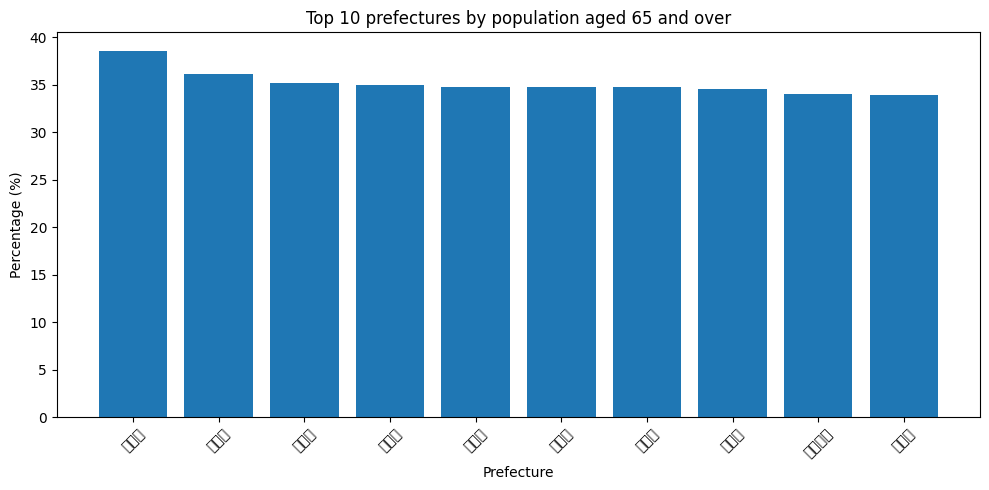

In [7]:
top10 = result_df.sort_values('65歳以上人口割合(%)', ascending=False).head(10)

plt.figure(figsize=(10, 5))
plt.bar(top10['都道府県'], top10['65歳以上人口割合(%)'])
plt.title('Top 10 prefectures by population aged 65 and over')
plt.xlabel('Prefecture')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. 分析してわかったこと
今回のデータでは、65歳以上人口の割合が30%以上の都道府県は **33県** だった。割合が最も高かったのは **秋田県で38.60%**、次いで高知県が36.09%、山口県が35.19%だった。

この結果から、今回のデータでは多くの都道府県で65歳以上人口の割合が30%以上になっていることがわかった。最も高い秋田県は、総人口930,000人のうち65歳以上人口が359,000人だった。

### 予想との比較
30%以上の都道府県が33県あり、予想よりも多くの県で高い割合になっていた。

### この分析の限界
このCSVに記録された値を使った結果であり、データの調査年や集計方法を確認しないまま、現在の状況と同じだとは断定できない。また、割合だけでは高齢化の原因まではわからない。

## 8. 使った方法
- 使用データ：授業で配布された `japan.csv`
- 使用ライブラリ：pandas、matplotlib
- 使用した授業内容：CSVの読み込み、`head()`、`info()`、`describe()`、`for`ループ、`if`文、リスト、`append()`、件数の確認、グラフ化
- 外部データは使用していない。